In [29]:
import pandas as pd

hits = pd.read_csv('pep_hits_wo_taxa_to_remove_091826.csv')

peps_metadata = pd.read_csv('lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')

In [30]:
lasv_hits = hits.loc[hits['species'] == 'Mammarenavirus lassaense'].sort_values(by='sensitivity', ascending=False)

In [31]:
"""

## all RPK data

df_all_rpk_avg = pd.read_csv("./preprocessing/rpk_df_technical_replicates_samples_passing_readcounts_100k_all_averaged_071626.csv")
df_all_rpk_avg = df_all_rpk_avg.set_index('peptide')
df_avg = df_all_rpk_avg

"""

'\n\n## all RPK data\n\ndf_all_rpk_avg = pd.read_csv("./preprocessing/rpk_df_technical_replicates_samples_passing_readcounts_100k_all_averaged_071626.csv")\ndf_all_rpk_avg = df_all_rpk_avg.set_index(\'peptide\')\ndf_avg = df_all_rpk_avg\n\n'

In [32]:
metadata = pd.read_csv("./preprocessing/master_sample_metadata_060626.csv")

### z score over us healthies

In [33]:
"""
import numpy as np

hbdb_df = pd.read_csv("./preprocessing/hbdb_pass_100k_techreps_averaged_071626.csv").set_index("peptide")

df_avg = df_avg[df_avg.max(axis=1) > 5]

cohort_df = df_avg.filter(regex='(^S-|^C-)')

mat = cohort_df.apply(pd.to_numeric, errors="coerce").fillna(0.0) #converts every column to a numeric type, if cannot be converted, fills with Nan, but then later NaN gets converted to 0.0

#log transforming before z-scoring
log_mat = np.log10(mat + 1.0)

log_hbdb = np.log10(hbdb_df + 1.0)

log_hbdb_mean = log_hbdb.mean(axis=1)

log_hbdb_std = log_hbdb.std(axis=1, ddof=1)
#to prevent inflated z-scores set threshold above a small percentile of the nonzero std
#quantile 0.01 picks a value where roughly the bottom 1% of peptides sit at or below it. so it's
#grounded by a small group of low-variance peptides rather than a single outlier. 
floor = log_hbdb_std[log_hbdb_std > 0].quantile(0.01)
log_hbdb_std = log_hbdb_std.clip(lower=floor)

#z-score using healthy controls as reference
z_mat = log_mat.sub(log_hbdb_mean, axis=0).div(log_hbdb_std, axis=0) #this aligns by peptide index
z_mat = z_mat.fillna(0.0)

z_mat.to_csv('z_score_df_SL_all_tp_over_US_101826.csv')

"""

'\nimport numpy as np\n\nhbdb_df = pd.read_csv("./preprocessing/hbdb_pass_100k_techreps_averaged_071626.csv").set_index("peptide")\n\ndf_avg = df_avg[df_avg.max(axis=1) > 5]\n\ncohort_df = df_avg.filter(regex=\'(^S-|^C-)\')\n\nmat = cohort_df.apply(pd.to_numeric, errors="coerce").fillna(0.0) #converts every column to a numeric type, if cannot be converted, fills with Nan, but then later NaN gets converted to 0.0\n\n#log transforming before z-scoring\nlog_mat = np.log10(mat + 1.0)\n\nlog_hbdb = np.log10(hbdb_df + 1.0)\n\nlog_hbdb_mean = log_hbdb.mean(axis=1)\n\nlog_hbdb_std = log_hbdb.std(axis=1, ddof=1)\n#to prevent inflated z-scores set threshold above a small percentile of the nonzero std\n#quantile 0.01 picks a value where roughly the bottom 1% of peptides sit at or below it. so it\'s\n#grounded by a small group of low-variance peptides rather than a single outlier. \nfloor = log_hbdb_std[log_hbdb_std > 0].quantile(0.01)\nlog_hbdb_std = log_hbdb_std.clip(lower=floor)\n\n#z-score usi

In [34]:
z_mat = pd.read_csv('z_score_df_SL_all_tp_over_US_101826.csv')

### keep participants with >= 2 time points

In [35]:
n_tp = metadata.groupby('participant_id')['sample_id'].nunique()

longitudinal = n_tp[n_tp >= 2].index

meta_long = metadata[metadata['participant_id'].isin(longitudinal)]

In [36]:
meta_long.head(2)

,sample_id,participant_id,collection_date,collection_year,collection_month,collection_year_month,baseline_date,days_since_baseline,years_since_baseline,visit_number,...,lassa_ID,lassa_Enrolled_Type,lassa_District,lassa_Chiefdom,lassa_VillageTown,missing_sex,missing_age_years,missing_district,missing_chiefdom,missing_village
3,C-110-1_2_A5,C-110-1,12/10/18,2018,12,2018-12,12/10/18,0,0.00,1,...,110-1,Contact to 110,Kenema,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C-110-1_6_A4,C-110-1,3/11/22,2022,3,2022-03,12/10/18,1187,3.25,2,...,110-1,Contact to 110,Kenema,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
z_mat = z_mat.set_index('peptide')

#subset to lasv hits
z_mat_lasv_hits = z_mat.loc[lasv_hits.peptide]

#make a long df out of it
long_lasv_hits = z_mat_lasv_hits.reset_index().melt(id_vars='peptide', var_name='sample_id', value_name='z_score').merge(meta_long, on='sample_id', how='inner')

#merge the protein name and protein std sequence etc to the long df
peps_metadata['peptide'] = peps_metadata['seq_id']
long_lasv_hits = long_lasv_hits.merge(peps_metadata[['peptide', 'sequence', 'protein_name', 'protein_std']], on='peptide', how='inner')

#peptide is reactive if z score over us healthies > 3
long_lasv_hits['reactive'] = long_lasv_hits['z_score'] > 3


In [38]:
long_lasv_hits.peptide.nunique()

lasv_peptides = lasv_hits.peptide

### restrict longitudinal data to the predefined LASV hits

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Restrict longitudinal data to ONLY these fixed LASV hits
lasv_long = long_lasv_hits

lasv_long["years_since_baseline"] = (
    lasv_long["days_since_baseline"] / 365.25
)

print("LASV hit peptides:", len(lasv_peptides))
print("Participants:", lasv_long["participant_id"].nunique())

LASV hit peptides: 76
Participants: 257


In [40]:
print(lasv_long["reactive"].value_counts(dropna=False))

reactive
False    48961
True      5303
Name: count, dtype: int64


In [41]:
lasv_long.loc[lasv_long['participant_id'] == 'C-451-3']['collection_date'].unique()

array(['9/23/19', '12/8/18'], dtype=object)

## bin follow-up time because people weren't samples exactly at 1, 2, 3 years

In [42]:
lasv_long["year_bin"] = np.floor( #floor forces to go down to the integer below
    lasv_long["years_since_baseline"] + 0.5
).astype(int)

lasv_long["year_bin"].value_counts().sort_index()

year_bin
0    20216
1     6840
2     8816
3    12692
4      684
5     2128
6     2888
Name: count, dtype: int64

## calculate cohort prevalence for every lasv peptide at every time

In [43]:
lasv_long['Category'].unique()

array(['C', 'S'], dtype=object)

In [44]:
peptide_time = (
    lasv_long
    .groupby(["peptide", "year_bin"])
    .agg(
        prevalence=("reactive", "mean"),
        n=("participant_id", "nunique")
    )
    .reset_index()
)

peptide_time["prevalence_pct"] = (
    100 * peptide_time["prevalence"]
)

In [45]:
peptide_time

,peptide,year_bin,prevalence,n,prevalence_pct
0,AHC95546.1|polymerase|Mammarenavirus_lassaense...,0,0.075188,247,7.518797
1,AHC95546.1|polymerase|Mammarenavirus_lassaense...,1,0.100000,81,10.000000
2,AHC95546.1|polymerase|Mammarenavirus_lassaense...,2,0.051724,116,5.172414
3,AHC95546.1|polymerase|Mammarenavirus_lassaense...,3,0.071856,144,7.185629
4,AHC95546.1|polymerase|Mammarenavirus_lassaense...,4,0.000000,9,0.000000
...,...,...,...,...,...
527,XQN12076.1|polymerase|Mammarenavirus_lassaense...,2,0.103448,116,10.344828
528,XQN12076.1|polymerase|Mammarenavirus_lassaense...,3,0.107784,144,10.778443
529,XQN12076.1|polymerase|Mammarenavirus_lassaense...,4,0.222222,9,22.222222
530,XQN12076.1|polymerase|Mammarenavirus_lassaense...,5,0.071429,28,7.142857


### plot every lasv peptide longitudinally

Participants per bin:
time_bin
Baseline     246
0–1 year      47
1–2 years    153
2–3 years     45
>3 years     151
dtype: int64

Showing 6 of 76 LASV peptides


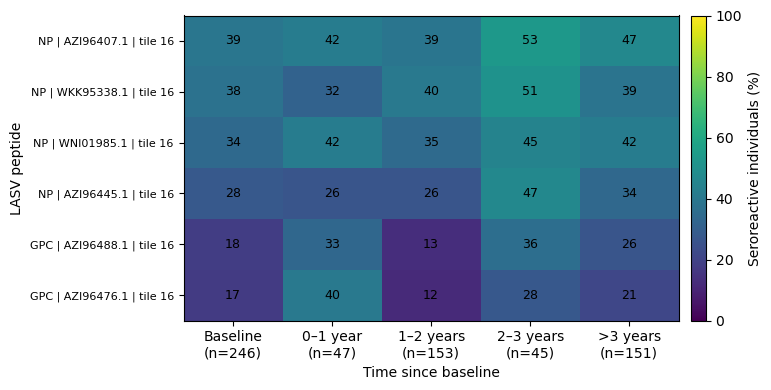

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def short_lasv_label(s):
    parts = str(s).split("|")

    accession = parts[0]
    annotation = parts[1].lower() if len(parts) > 1 else ""

    if "nucleoprotein" in annotation:
        protein = "NP"
    elif "polymerase" in annotation:
        protein = "L"
    elif "precursor" in annotation:
        protein = "GPC"
    elif "z protein" in annotation or annotation == "protein":
        protein = "Z"
    else:
        protein = annotation

    # Your strings appear to end in something like tile_16
    tile = ""
    if len(parts) > 0:
        last = parts[-1]
        if "tile_" in last:
            tile = last.split("tile_")[-1]

    if tile:
        return f"{protein} | {accession} | tile {tile}"
    else:
        return f"{protein} | {accession}"



# bins for visualization

bins = [
    -0.01,
    0.01,      # baseline
    1.0,       # 0–1 year
    2.0,       # 1–2 years
    3.0,       # 2–3 years
    np.inf     # >3 years
]

labels = [
    "Baseline",
    "0–1 year",
    "1–2 years",
    "2–3 years",
    ">3 years"
]

lasv_long["time_bin"] = pd.cut(
    lasv_long["years_since_baseline"],
    bins=bins,
    labels=labels,
    include_lowest=True, #make the first bin include its lower edge (only matters if bins[0]==0), not needed here
    right=True #edge values go in the bin on their left e.g. 1 -> 0-1 bin. means each bin includes its right edge. 
)

# 3. Number of UNIQUE participants per bin

n_by_bin = (
    lasv_long[
        ["participant_id", "time_bin"]
    ]
    .drop_duplicates()
    .groupby("time_bin", observed=True)
    .size()
)

print("Participants per bin:")
print(n_by_bin)


# 4. Peptide prevalence within each bin

peptide_time_binned = (
    lasv_long
    .groupby(
        ["peptide", "time_bin"],
        observed=True
    )
    .agg(
        prevalence=("reactive", "mean"),
        n=("participant_id", "nunique")
    )
    .reset_index()
)

peptide_time_binned["prevalence_pct"] = (
    peptide_time_binned["prevalence"] * 100
)


# 5. Create heatmap matrix

heat_binned = peptide_time_binned.pivot(
    index="peptide",
    columns="time_bin",
    values="prevalence_pct"
)

# Force correct chronological order
heat_binned = heat_binned.reindex(
    columns=labels
)

# 6. Keep peptides reaching >=30% prevalence at ANY time
#    DISPLAY FILTER ONLY

heat_main = heat_binned.loc[
    heat_binned.max(axis=1) >= 30
].copy()

# Sort by baseline prevalence
heat_main = heat_main.sort_values(
    "Baseline",
    ascending=False
)

print(
    f"\nShowing {len(heat_main)} "
    f"of {len(heat_binned)} LASV peptides"
)

# 7. Plot

fig, ax = plt.subplots(
    figsize=(8, max(4, len(heat_main) * 0.5))
)

im = ax.imshow(
    heat_main.values,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

vals = heat_main.values

for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        if np.isnan(v):
            continue
        ax.text(
            j, i, f"{v:.0f}",
            ha="center", va="center",
            fontsize=9,
            color="white" if v > 55 else "black"
        )

# X labels including n
xlabels = [
    f"{col}\n(n={n_by_bin.get(col, 0)})"
    for col in heat_main.columns
]

ax.set_xticks(
    range(len(heat_main.columns))
)
ax.set_xticklabels(xlabels)


# Y labels
ax.set_yticks(
    range(len(heat_main.index))
)
ax.set_yticklabels(
    [
        short_lasv_label(x)
        for x in heat_main.index
    ],
    fontsize=8
)

ax.set_xlabel("Time since baseline")
ax.set_ylabel("LASV peptide")

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Seroreactive individuals (%)"
)

plt.tight_layout()
plt.show()

In [47]:
surv_long = lasv_long[
    lasv_long["sample_id"].str.startswith('S-')
].copy()

print(
    "Survivors:",
    surv_long["participant_id"].nunique()
)

# n per visualization bin
n_surv_bin = (
    surv_long[["participant_id", "time_bin"]]
    .drop_duplicates()
    .groupby("time_bin", observed=True)
    .size()
)

print(n_surv_bin)

Survivors: 88
time_bin
Baseline     84
0–1 year     35
1–2 years    31
2–3 years    40
>3 years     57
dtype: int64


In [48]:
surv_peptide_time = (
    surv_long
    .groupby(
        ["peptide", "time_bin"],
        observed=True #only get combinations present, so only peptides which have a time bin
    )
    .agg(
        prevalence=("reactive", "mean"),
        n=("participant_id", "nunique")
    )
    .reset_index()
)

surv_peptide_time["prevalence_pct"] = (
    surv_peptide_time["prevalence"] * 100
)

heat_surv = surv_peptide_time.pivot(
    index="peptide",
    columns="time_bin",
    values="prevalence_pct"
)

# same column order as your existing figure
time_order = [
    "Baseline",
    "0–1 year",
    "1–2 years",
    "2–3 years",
    ">3 years"
]


In [49]:
heat_surv_main = heat_surv.loc[
    heat_surv["Baseline"] >= 30
].copy()

heat_surv_main = heat_surv_main.sort_values(
    "Baseline",
    ascending=False
)

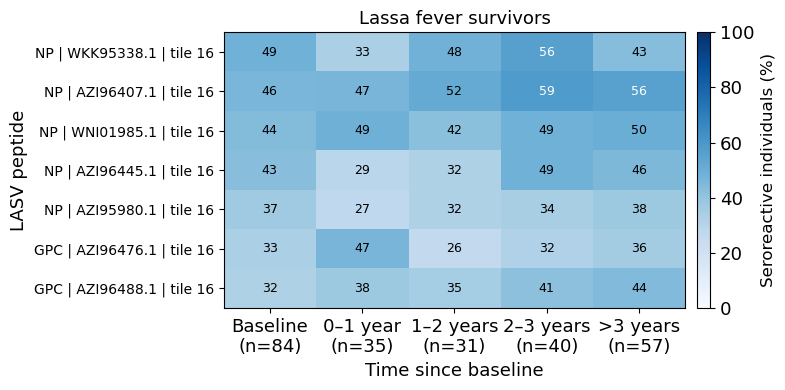

In [50]:
fig, ax = plt.subplots(
    figsize=(8, max(4, len(heat_surv_main) * 0.5))
)

im = ax.imshow( #this is the matplotlib command that displays a 2D array as an image
    heat_surv_main.values,
    aspect="auto",
    interpolation="nearest",
    cmap='Blues',
    vmin=0,
    vmax=100
)

vals = heat_surv_main.values

for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        if np.isnan(v):
            continue
        ax.text(
            j, i, f"{v:.0f}",
            ha="center", va="center",
            fontsize=9,
            color="white" if v > 55 else "black"
        )


xlabels = [
    f"{col}\n(n={n_surv_bin.get(col, 0)})"
    for col in heat_surv_main.columns
]

ax.set_xticks(range(len(heat_surv_main.columns)))
ax.set_xticklabels(xlabels)

ax.set_yticks(range(len(heat_surv_main.index)))
ax.set_yticklabels(
    [short_lasv_label(x) for x in heat_surv_main.index],
    fontsize=10
)

ax.set_xlabel("Time since baseline", fontsize=13)
ax.set_ylabel("LASV peptide", fontsize=13)
ax.set_title("Lassa fever survivors", fontsize=13)

ax.set_xticklabels(xlabels, fontsize=13)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.ax.tick_params(labelsize=13)
cbar.set_label("Seroreactive individuals (%)", fontsize=12)

plt.tight_layout()

plt.savefig('./svg_figures/longitudinal_heatmap_top_peps_survivors.svg', format='svg')
plt.show()

In [51]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# The peptides actually displayed in survivor heatmap
surv_peptides = heat_surv_main.index.tolist()

results = []

for peptide in surv_peptides:

    d = surv_long[
        surv_long["peptide"] == peptide
    ].copy()

    d = d.dropna(
        subset=[
            "reactive",
            "years_since_baseline",
            "participant_id"
        ]
    )

    # Need both reactive and non-reactive observations
    if d["reactive"].nunique() < 2:
        continue

    # Need >1 longitudinal time
    if d["years_since_baseline"].nunique() < 2:
        continue

    model = smf.gee(
        formula="reactive ~ years_since_baseline",
        groups="participant_id",
        data=d,
        family=sm.families.Binomial(),
        cov_struct=sm.cov_struct.Exchangeable()
    ).fit()

    beta = model.params["years_since_baseline"]
    ci = model.conf_int().loc["years_since_baseline"]

    results.append({
        "peptide": peptide,
        "label": short_lasv_label(peptide),
        "n_participants": d["participant_id"].nunique(),
        "OR_per_year": np.exp(beta),
        "CI_low": np.exp(ci.iloc[0]),
        "CI_high": np.exp(ci.iloc[1]),
        "p_value": model.pvalues["years_since_baseline"]
    })

surv_gee = pd.DataFrame(results)

# FDR correction across these predefined dominant survivor epitopes
surv_gee["FDR"] = multipletests(
    surv_gee["p_value"],
    method="fdr_bh"
)[1]

surv_gee["significant_FDR"] = surv_gee["FDR"] < 0.05

display(
    surv_gee[
        [
            "label",
            "n_participants",
            "OR_per_year",
            "CI_low",
            "CI_high",
            "p_value",
            "FDR",
            "significant_FDR"
        ]
    ].sort_values("FDR")
)

,label,n_participants,OR_per_year,CI_low,CI_high,p_value,FDR,significant_FDR
6,GPC | AZI96488.1 | tile 16,88,0.913624,0.831536,1.003815,0.060014,0.420095,False
3,NP | AZI96445.1 | tile 16,88,0.933406,0.848052,1.027350,0.158984,0.556444,False
1,NP | AZI96407.1 | tile 16,88,0.955556,0.860914,1.060603,0.392936,0.916851,False
0,NP | WKK95338.1 | tile 16,88,1.019271,0.916189,1.133951,0.725679,0.967546,False
2,NP | WNI01985.1 | tile 16,88,0.990536,0.901695,1.088130,0.842781,0.967546,False
4,NP | AZI95980.1 | tile 16,88,0.997810,0.897820,1.108936,0.967546,0.967546,False
5,GPC | AZI96476.1 | tile 16,88,1.023177,0.929035,1.126858,0.641747,0.967546,False


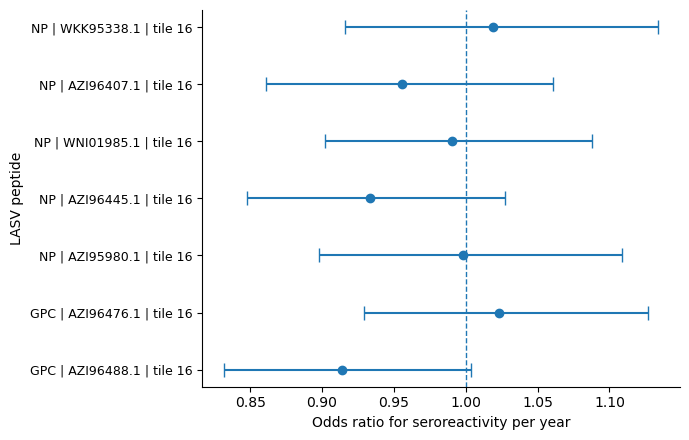

In [52]:
# Preserve exactly the same top-to-bottom order as heatmap
order = {
    peptide: i
    for i, peptide in enumerate(heat_surv_main.index)
}

forest = surv_gee.copy()
forest["order"] = forest["peptide"].map(order)

forest = (
    forest
    .sort_values("order")
    .reset_index(drop=True)
)

y = np.arange(len(forest))

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.errorbar(
    forest["OR_per_year"],
    y,
    xerr=[
        forest["OR_per_year"] - forest["CI_low"],
        forest["CI_high"] - forest["OR_per_year"]
    ],
    fmt="o",
    capsize=5
)

ax.axvline(
    1,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y)
ax.set_yticklabels(
    forest["label"],
    fontsize=9
)

ax.invert_yaxis()

ax.set_xlabel("Odds ratio for seroreactivity per year")
ax.set_ylabel("LASV peptide")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### ok above is important

In [53]:
surv_peptide_time = (
    surv_long
    .groupby(
        ["peptide", "time_bin"],
        observed=True
    )
    .agg(
        prevalence=("reactive", "mean"),
        n=("participant_id", "nunique")
    )
    .reset_index()
)

surv_peptide_time["prevalence_pct"] = (
    surv_peptide_time["prevalence"] * 100
)

heat_surv = surv_peptide_time.pivot(
    index="peptide",
    columns="time_bin",
    values="prevalence_pct"
)

# same column order as your existing figure
time_order = [
    "Baseline",
    "0–1 year",
    "1–2 years",
    "2–3 years",
    ">3 years"
]

heat_surv = heat_surv.reindex(columns=time_order)

# IMPORTANT:
# use the SAME peptides as your full-cohort main figure,
# rather than selecting a new survivor-specific >=10% set
heat_surv_main = heat_surv.reindex(
    heat_main.index
)

In [54]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# ============================================================
# 1. Continuous time
# ============================================================

lasv_long = lasv_long.copy()

lasv_long["years_since_baseline"] = (
    lasv_long["days_since_baseline"] / 365.25
)

# Make sure reactive is numeric 0/1
lasv_long["reactive"] = lasv_long["reactive"].astype(int)

print(lasv_long["reactive"].value_counts())


# ============================================================
# 2. Test ALL predefined LASV hits
# ============================================================

# If lasv_long is already restricted to your predefined LASV hits:
peptides_to_test = lasv_long["peptide"].unique()

print(f"Testing {len(peptides_to_test)} LASV peptides")


# ============================================================
# 3. One longitudinal logistic GEE per peptide
# ============================================================

results = []

for peptide in peptides_to_test:

    d = lasv_long[
        lasv_long["peptide"] == peptide
    ].copy()

    d = d.dropna(
        subset=[
            "reactive",
            "years_since_baseline",
            "participant_id"
        ]
    )

    # Cannot fit logistic model if everybody is always
    # positive or everybody is always negative
    if d["reactive"].nunique() < 2:
        continue

    # Need observations at >1 time
    if d["years_since_baseline"].nunique() < 2:
        continue

    try:

        model = smf.gee(
            formula="reactive ~ years_since_baseline",
            groups="participant_id",
            data=d,
            family=sm.families.Binomial(),
            cov_struct=sm.cov_struct.Exchangeable()
        ).fit()

        beta = model.params["years_since_baseline"]

        ci = model.conf_int().loc[
            "years_since_baseline"
        ]

        results.append({
            "peptide": peptide,
            "label": short_lasv_label(peptide),

            "n_participants":
                d["participant_id"].nunique(),

            "n_observations":
                len(d),

            "beta":
                beta,

            # OR for each additional year
            "OR_per_year":
                np.exp(beta),

            "CI_low":
                np.exp(ci.iloc[0]),

            "CI_high":
                np.exp(ci.iloc[1]),

            "p_value":
                model.pvalues["years_since_baseline"]
        })

    except Exception as e:
        print(
            "Failed:",
            short_lasv_label(peptide),
            e
        )


gee_results = pd.DataFrame(results)

print(
    f"Successfully modeled "
    f"{len(gee_results)} peptides"
)

reactive
0    48961
1     5303
Name: count, dtype: int64
Testing 76 LASV peptides
Successfully modeled 76 peptides


In [55]:
# ============================================================
# 4. Multiple-testing correction
# ============================================================

gee_results["FDR"] = multipletests(
    gee_results["p_value"],
    method="fdr_bh"
)[1]

gee_results["significant_FDR"] = (
    gee_results["FDR"] < 0.05
)

gee_results = gee_results.sort_values(
    "FDR"
)

display(
    gee_results[
        [
            "label",
            "n_participants",
            "OR_per_year",
            "CI_low",
            "CI_high",
            "p_value",
            "FDR",
            "significant_FDR"
        ]
    ]
)

print(
    "\nSignificant after FDR:",
    gee_results["significant_FDR"].sum()
)

,label,n_participants,OR_per_year,CI_low,CI_high,p_value,FDR,significant_FDR
3,NP | AZI96445.1 | tile 16,257,1.084755,0.997526,1.179613,0.057165,0.684286,False
7,GPC | AZI96488.1 | tile 16,257,1.072653,0.972709,1.182867,0.159882,0.684286,False
6,NP | ANH09741.1 | tile 6,257,0.915013,0.820400,1.020537,0.110731,0.684286,False
13,L | USR47367.1 | tile 39,257,1.081077,0.973245,1.200855,0.145913,0.684286,False
20,L | AZI95898.1 | tile 41,257,0.908204,0.793530,1.039449,0.162068,0.684286,False
...,...,...,...,...,...,...,...,...
67,L | AZI95816.1 | tile 21,257,1.051307,0.877957,1.258884,0.586287,0.941019,False
62,L | AZI96098.1 | tile 90,257,0.991872,0.829388,1.186188,0.928760,0.964849,False
4,NP | AZI95980.1 | tile 16,257,1.002918,0.914126,1.100334,0.950881,0.964849,False
1,NP | WKK95338.1 | tile 16,257,0.997489,0.918851,1.082857,0.952154,0.964849,False



Significant after FDR: 0


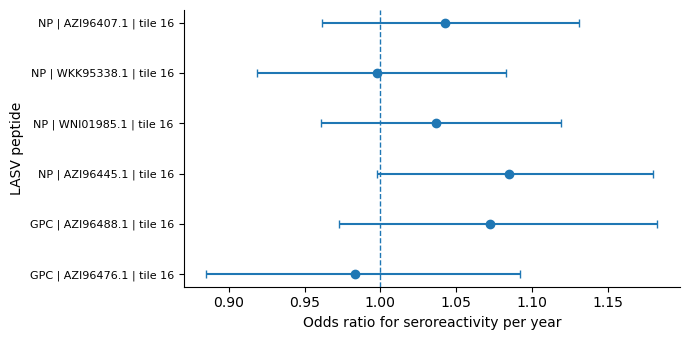

In [56]:
# ============================================================
# 5. Forest plot for peptides displayed in heatmap
# ============================================================

display_peptides = set(heat_main.index)

forest = (
    gee_results[
        gee_results["peptide"].isin(display_peptides)
    ]
    .copy()
)

# Keep same order as heatmap
order = {
    peptide: i
    for i, peptide in enumerate(heat_main.index)
}

forest["plot_order"] = forest["peptide"].map(order)

forest = (
    forest
    .sort_values("plot_order")
    .reset_index(drop=True)
)

y = np.arange(len(forest))

fig, ax = plt.subplots(
    figsize=(7, max(3.5, len(forest) * 0.55))
)

ax.errorbar(
    forest["OR_per_year"],
    y,
    xerr=[
        forest["OR_per_year"] - forest["CI_low"],
        forest["CI_high"] - forest["OR_per_year"]
    ],
    fmt="o",
    capsize=3
)

# OR = 1 means no temporal change
ax.axvline(
    1,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y)

ax.set_yticklabels(
    [
        short_lasv_label(p)
        for p in forest["peptide"]
    ],
    fontsize=8
)

# Same top-to-bottom ordering as heatmap
ax.invert_yaxis()

ax.set_xlabel(
    "Odds ratio for seroreactivity per year"
)

ax.set_ylabel("LASV peptide")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### next

In [57]:
def get_lasv_protein(s):
    parts = str(s).split("|")
    annotation = parts[1].lower() if len(parts) > 1 else ""

    if "nucleoprotein" in annotation:
        return "NP"
    elif "polymerase" in annotation:
        return "L"
    elif "precursor" in annotation:
        return "GPC"
    elif "z protein" in annotation or annotation == "protein":
        return "Z"
    else:
        return "Other"


lasv_long["protein"] = (
    lasv_long["peptide"]
    .map(get_lasv_protein)
)

In [58]:
protein_time = (
    lasv_long
    .groupby(
        ["protein", "year_bin", "peptide"]
    )["reactive"]
    .mean()
    .reset_index(name="prevalence")
)

protein_summary = (
    protein_time
    .groupby(
        ["protein", "year_bin"]
    )["prevalence"]
    .agg(
        mean="mean",
        median="median",
        sem="sem",
        n_peptides="count"
    )
    .reset_index()
)

protein_summary["mean_pct"] = (
    protein_summary["mean"] * 100
)

protein_summary["sem_pct"] = (
    protein_summary["sem"] * 100
)

display(protein_summary)

,protein,year_bin,mean,median,sem,n_peptides,mean_pct,sem_pct
0,GPC,0,0.120301,0.093985,0.028581,5,12.030075,2.858132
1,GPC,1,0.171111,0.133333,0.048253,5,17.111111,4.825345
2,GPC,2,0.081034,0.086207,0.015324,5,8.103448,1.532447
3,GPC,3,0.108982,0.071856,0.030615,5,10.898204,3.061514
4,GPC,4,0.177778,0.222222,0.075359,5,17.777778,7.535922
5,GPC,5,0.207143,0.107143,0.080178,5,20.714286,8.017837
6,GPC,6,0.247368,0.263158,0.093634,5,24.736842,9.363393
7,L,0,0.073002,0.067669,0.004587,43,7.300227,0.458682
8,L,1,0.074419,0.055556,0.007743,43,7.441860,0.774311
9,L,2,0.079190,0.068966,0.005978,43,7.919006,0.597821


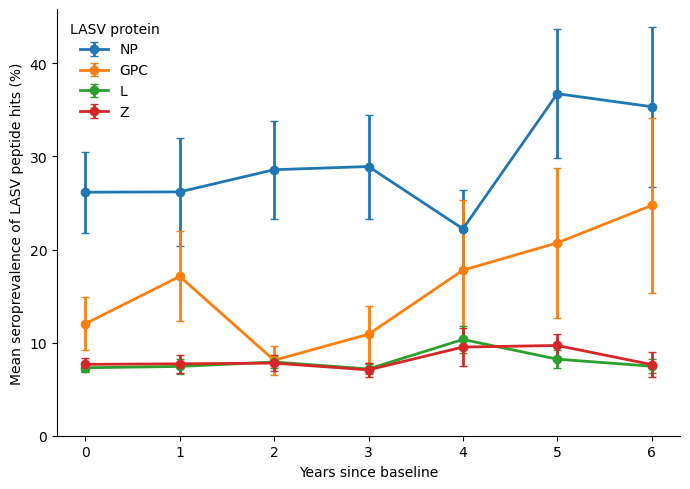

In [59]:
fig, ax = plt.subplots(figsize=(7, 5))

protein_order = ["NP", "GPC", "L", "Z"]

for protein in protein_order:

    d = protein_summary[
        protein_summary["protein"] == protein
    ].sort_values("year_bin")

    if len(d) == 0:
        continue

    ax.errorbar(
        d["year_bin"],
        d["mean_pct"],
        yerr=d["sem_pct"],
        marker="o",
        linewidth=2,
        capsize=3,
        label=protein
    )

ax.set_xlabel("Years since baseline")
ax.set_ylabel(
    "Mean seroprevalence of LASV peptide hits (%)"
)

ax.set_ylim(bottom=0)

ax.legend(
    title="LASV protein",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

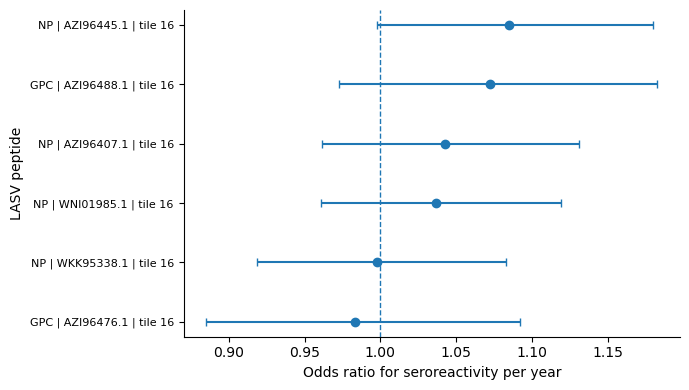

In [60]:
main_peptides = set(heat_main.index)

forest = (
    gee_results[
        gee_results["peptide"].isin(main_peptides)
    ]
    .copy()
    .sort_values("OR_per_year")
)

# Make labels unique
forest["plot_label"] = (
    forest["peptide"]
    .map(short_lasv_label)
)

y = np.arange(len(forest))

fig, ax = plt.subplots(
    figsize=(7, max(4, len(forest) * 0.4))
)

ax.errorbar(
    forest["OR_per_year"],
    y,
    xerr=[
        forest["OR_per_year"] - forest["CI_low"],
        forest["CI_high"] - forest["OR_per_year"]
    ],
    fmt="o",
    capsize=3
)

ax.axvline(
    1,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y)
ax.set_yticklabels(
    forest["plot_label"],
    fontsize=8
)

ax.set_xlabel(
    "Odds ratio for seroreactivity per year"
)

ax.set_ylabel("LASV peptide")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

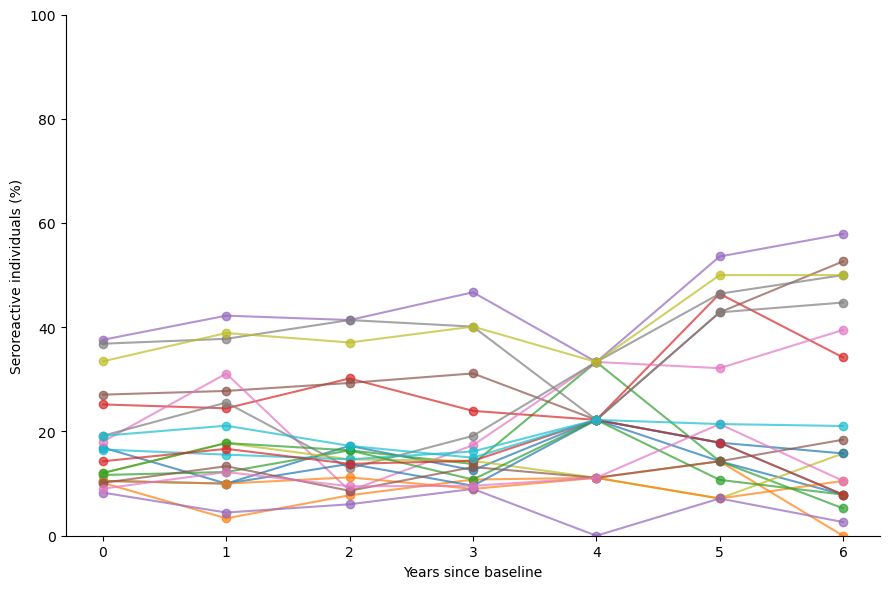

In [61]:
top_peptides = (
    lasv_hits
    .head(20)["peptide"]
    .tolist()
)

top = peptide_time[
    peptide_time["peptide"].isin(top_peptides)
].copy()

fig, ax = plt.subplots(figsize=(9, 6))

for peptide, d in top.groupby("peptide"):
    d = d.sort_values("year_bin")

    ax.plot(
        d["year_bin"],
        d["prevalence_pct"],
        marker="o",
        linewidth=1.5,
        alpha=0.7
    )

ax.set_xlabel("Years since baseline")
ax.set_ylabel("Seroreactive individuals (%)")
ax.set_ylim(0, 100)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### next

In [62]:
is_base = long_lasv_hits['days_since_baseline'] == long_lasv_hits.groupby('participant_id')['days_since_baseline'].transform('min')

baseline = long_lasv_hits[is_base]

#each participant's baeline reactive peptide set from the filtered sens spec peptide hits
base_set = baseline.loc[baseline['reactive'], ['participant_id', 'peptide']]

#trk is filtered on the baseline reactive ppetides for each individual
trk = long_lasv_hits.merge(base_set, on=['participant_id', 'peptide']) #inner merge preseves only participant peptide pairs present in base_set, across all tps

In [63]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

n_base  = trk.groupby('participant_id')['peptide'].nunique().rename('n_baseline')

# --- 1. breadth: retained / total / gained ---
retained = (trk.groupby(['participant_id', 'days_since_baseline'])['reactive']
                  .sum().reset_index(name='n_retained'))

total = (long_lasv_hits.groupby(['participant_id', 'days_since_baseline'])['reactive']
                          .sum().reset_index(name='n_total'))

b = (retained.merge(total, on=['participant_id', 'days_since_baseline'])
             .merge(n_base, on='participant_id'))
b['pct_retained'] = 100 * b['n_retained'] / b['n_baseline']
b['n_gained']     = b['n_total'] - b['n_retained']

# --- 2. magnitude ---
mag = (trk.groupby(['participant_id', 'days_since_baseline'])['z_score']
             .median().reset_index(name='median_z'))
b = b.merge(mag, on=['participant_id', 'days_since_baseline'])

# sanity: 100% at each participant's first timepoint
print(b.loc[b.groupby('participant_id')['days_since_baseline'].idxmin(), 'pct_retained'].describe())


count    254.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: pct_retained, dtype: float64


In [64]:
b

,participant_id,days_since_baseline,n_retained,n_total,n_baseline,pct_retained,n_gained,median_z
0,C-110-1,0,1,1,1,100.000000,0,3.137539
1,C-110-1,1187,1,5,1,100.000000,4,3.720506
2,C-110-2,0,3,3,3,100.000000,0,3.894639
3,C-110-2,1188,0,2,3,0.000000,2,0.546180
4,C-110-3,0,6,6,6,100.000000,0,6.177971
...,...,...,...,...,...,...,...,...
703,S-512,454,3,8,8,37.500000,5,2.700704
704,S-513,0,3,3,3,100.000000,0,4.231874
705,S-513,454,0,0,3,0.000000,0,-1.406696
706,S-514,0,14,14,14,100.000000,0,10.835314


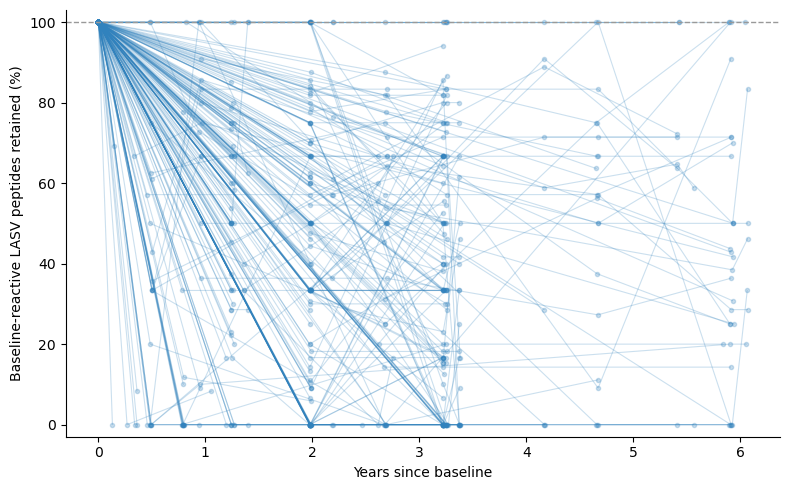

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))

for pid, g in b.sort_values('days_since_baseline').groupby('participant_id'):
    ax.plot(
        g['days_since_baseline'] / 365.25,
        g['pct_retained'],
        marker='o',
        ms=3,
        lw=0.8,
        alpha=0.25,
        color='#3182bd'
    )

ax.axhline(100, color='0.6', ls='--', lw=1)

ax.set(
    xlabel='Years since baseline',
    ylabel='Baseline-reactive LASV peptides retained (%)',
    ylim=(-3, 103)
)

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ============================================================
# Prepare longitudinal dataframe
# ============================================================

b = b.copy()

b["years_since_baseline"] = b["days_since_baseline"] / 365.25

# Number of baseline peptides that are no longer reactive
b["n_lost"] = b["n_baseline"] - b["n_retained"]

# Jaccard similarity:
# intersection = retained baseline peptides
# union = baseline peptides + newly gained peptides
b["jaccard"] = (
    b["n_retained"] /
    (b["n_baseline"] + b["n_gained"])
)

# Optional: breadth relative to baseline
b["breadth_ratio"] = b["n_total"] / b["n_baseline"]

# Quick checks
print(
    b[[
        "n_baseline",
        "n_retained",
        "n_lost",
        "n_gained",
        "n_total",
        "pct_retained",
        "jaccard",
        "breadth_ratio"
    ]].describe()
)

       n_baseline  n_retained      n_lost    n_gained     n_total  \
count  708.000000  708.000000  708.000000  708.000000  708.000000   
mean     7.436441    4.716102    2.720339    2.764124    7.480226   
std      4.749770    4.482235    3.377818    3.167107    4.477940   
min      1.000000    0.000000    0.000000    0.000000    0.000000   
25%      3.000000    1.000000    0.000000    0.000000    4.000000   
50%      6.000000    3.000000    2.000000    2.000000    7.000000   
75%     11.000000    7.000000    4.000000    4.000000   10.000000   
max     26.000000   26.000000   18.000000   16.000000   26.000000   

       pct_retained     jaccard  breadth_ratio  
count    708.000000  708.000000     708.000000  
mean      61.117838    0.520263       1.292110  
std       38.504937    0.400959       1.360779  
min        0.000000    0.000000       0.000000  
25%       28.571429    0.142857       0.846154  
50%       66.666667    0.454545       1.000000  
75%      100.000000    1.000000    

In [67]:
# ============================================================
# Binomial GEE: probability that a baseline peptide is retained
# ============================================================

gee_df = b[
    (b["n_baseline"] > 0) &
    b["n_retained"].notna() &
    b["years_since_baseline"].notna()
].copy()

# Proportion retained
gee_df["prop_retained"] = (
    gee_df["n_retained"] / gee_df["n_baseline"]
)

ret_model = smf.gee(
    formula="prop_retained ~ years_since_baseline",
    groups="participant_id",
    data=gee_df,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Exchangeable(),
    weights=gee_df["n_baseline"]
).fit()

print(ret_model.summary())

                               GEE Regression Results                              
Dep. Variable:               prop_retained   No. Observations:                  708
Model:                                 GEE   No. clusters:                      254
Method:                        Generalized   Min. cluster size:                   1
                      Estimating Equations   Max. cluster size:                   7
Family:                           Binomial   Mean cluster size:                 2.8
Dependence structure:         Exchangeable   Num. iterations:                    14
Date:                     Mon, 19 Oct 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         18:09:57
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                1.5789      0.086     18.273      0.000  

In [68]:
beta = ret_model.params["years_since_baseline"]

OR = np.exp(beta)
ci = ret_model.conf_int().loc["years_since_baseline"]

print(f"Odds ratio per year = {OR:.3f}")
print(
    f"95% CI = "
    f"{np.exp(ci.iloc[0]):.3f}–{np.exp(ci.iloc[1]):.3f}"
)
print(
    f"P = {ret_model.pvalues['years_since_baseline']:.3g}"
)

Odds ratio per year = 0.572
95% CI = 0.518–0.633
P = 1.31e-27


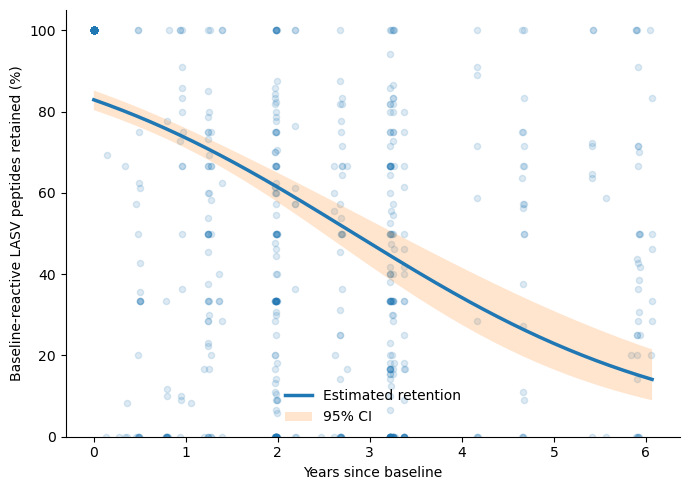

In [69]:
# Prediction grid
x_pred = np.linspace(
    0,
    gee_df["years_since_baseline"].max(),
    200
)

pred_df = pd.DataFrame({
    "years_since_baseline": x_pred
})

pred = ret_model.get_prediction(pred_df).summary_frame()

pred_df["predicted"] = pred["mean"]
pred_df["lower"] = pred["mean_ci_lower"]
pred_df["upper"] = pred["mean_ci_upper"]

# Convert to %
pred_df[["predicted", "lower", "upper"]] *= 100


fig, ax = plt.subplots(figsize=(7, 5))

# Individual observations in background
ax.scatter(
    gee_df["years_since_baseline"],
    gee_df["pct_retained"],
    alpha=0.15,
    s=20
)

# Model estimate
ax.plot(
    pred_df["years_since_baseline"],
    pred_df["predicted"],
    linewidth=2.5,
    label="Estimated retention"
)

# 95% CI
ax.fill_between(
    pred_df["years_since_baseline"],
    pred_df["lower"],
    pred_df["upper"],
    alpha=0.2,
    label="95% CI"
)

ax.set_xlabel("Years since baseline")
ax.set_ylabel("Baseline-reactive LASV peptides retained (%)")
ax.set_ylim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess

b = b.copy()

b["years_since_baseline"] = b["days_since_baseline"] / 365.25

# -------------------------------
# repertoire components
# -------------------------------

# baseline ∩ current
# already present:
# b["n_retained"]

# current repertoire size
# already present:
# b["n_total"]

# baseline repertoire size
# already present:
# b["n_baseline"]

# Peptides present now that were NOT present at baseline
b["n_gained"] = b["n_total"] - b["n_retained"]

# Peptides present at baseline but absent now
b["n_lost"] = b["n_baseline"] - b["n_retained"]

# Union = baseline + current - intersection
b["n_union"] = (
    b["n_baseline"]
    + b["n_total"]
    - b["n_retained"]
)

# Jaccard similarity
b["jaccard"] = b["n_retained"] / b["n_union"]

# Current breadth relative to baseline
b["breadth_ratio"] = b["n_total"] / b["n_baseline"]

# Absolute change in breadth
b["breadth_change"] = b["n_total"] - b["n_baseline"]

In [71]:
print(
    b[
        [
            "n_baseline",
            "n_retained",
            "n_lost",
            "n_gained",
            "n_total",
            "n_union",
            "jaccard",
            "breadth_ratio",
        ]
    ].describe()
)

# These should NEVER occur
print("Negative gained:", (b["n_gained"] < 0).sum())
print("Negative lost:", (b["n_lost"] < 0).sum())
print("Jaccard > 1:", (b["jaccard"] > 1).sum())

       n_baseline  n_retained      n_lost    n_gained     n_total     n_union  \
count  708.000000  708.000000  708.000000  708.000000  708.000000  708.000000   
mean     7.436441    4.716102    2.720339    2.764124    7.480226   10.200565   
std      4.749770    4.482235    3.377818    3.167107    4.477940    5.618660   
min      1.000000    0.000000    0.000000    0.000000    0.000000    1.000000   
25%      3.000000    1.000000    0.000000    0.000000    4.000000    6.000000   
50%      6.000000    3.000000    2.000000    2.000000    7.000000   10.000000   
75%     11.000000    7.000000    4.000000    4.000000   10.000000   14.000000   
max     26.000000   26.000000   18.000000   16.000000   26.000000   30.000000   

          jaccard  breadth_ratio  
count  708.000000     708.000000  
mean     0.520263       1.292110  
std      0.400959       1.360779  
min      0.000000       0.000000  
25%      0.142857       0.846154  
50%      0.454545       1.000000  
75%      1.000000       1

In [72]:
base = b.loc[
    b.groupby("participant_id")["days_since_baseline"].idxmin()
]

print(base[
    ["pct_retained", "jaccard", "breadth_ratio"]
].describe())

       pct_retained  jaccard  breadth_ratio
count         254.0    254.0          254.0
mean          100.0      1.0            1.0
std             0.0      0.0            0.0
min           100.0      1.0            1.0
25%           100.0      1.0            1.0
50%           100.0      1.0            1.0
75%           100.0      1.0            1.0
max           100.0      1.0            1.0


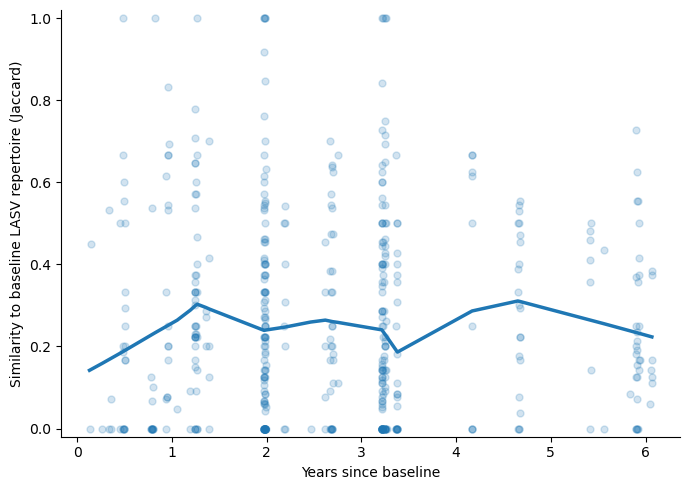

In [73]:
j = b[
    (b["years_since_baseline"] > 0) &
    b["jaccard"].notna()
].copy()

smooth = lowess(
    j["jaccard"],
    j["years_since_baseline"],
    frac=0.35,
    return_sorted=True
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    j["years_since_baseline"],
    j["jaccard"],
    alpha=0.20,
    s=25
)

ax.plot(
    smooth[:, 0],
    smooth[:, 1],
    linewidth=2.5
)

ax.set_xlabel("Years since baseline")
ax.set_ylabel("Similarity to baseline LASV repertoire (Jaccard)")
ax.set_ylim(-0.02, 1.02)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

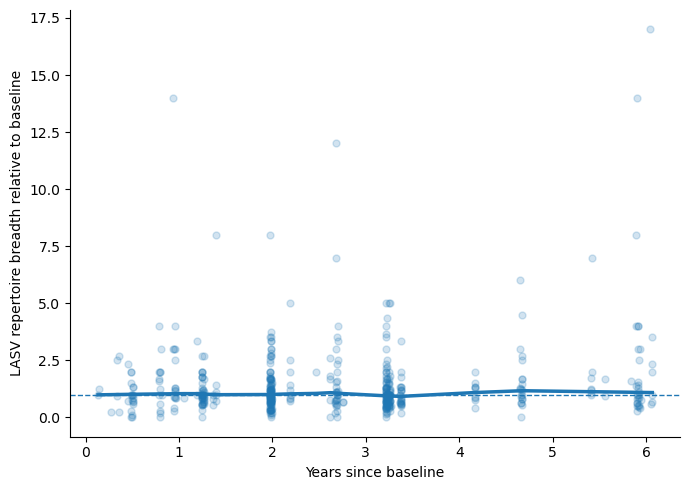

In [74]:
br = b[
    (b["years_since_baseline"] > 0) &
    b["breadth_ratio"].notna()
].copy()

smooth_br = lowess(
    br["breadth_ratio"],
    br["years_since_baseline"],
    frac=0.35,
    return_sorted=True
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    br["years_since_baseline"],
    br["breadth_ratio"],
    alpha=0.20,
    s=25
)

ax.plot(
    smooth_br[:, 0],
    smooth_br[:, 1],
    linewidth=2.5
)

# baseline breadth
ax.axhline(
    1,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Years since baseline")
ax.set_ylabel("LASV repertoire breadth relative to baseline")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [75]:
j_model = smf.mixedlm(
    "jaccard ~ years_since_baseline",
    data=j,
    groups=j["participant_id"]
).fit()

print(j_model.summary())

beta = j_model.params["years_since_baseline"]
ci = j_model.conf_int().loc["years_since_baseline"]

print(
    f"Jaccard change per year: {beta:.3f} "
    f"(95% CI {ci.iloc[0]:.3f} to {ci.iloc[1]:.3f}), "
    f"p={j_model.pvalues['years_since_baseline']:.3g}"
)

             Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    jaccard
No. Observations:     465        Method:                REML   
No. Groups:           252        Scale:                 0.0293 
Min. group size:      1          Log-Likelihood:        21.8752
Max. group size:      6          Converged:             Yes    
Mean group size:      1.8                                      
---------------------------------------------------------------
                     Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------
Intercept             0.297    0.022 13.755 0.000  0.255  0.339
years_since_baseline -0.013    0.006 -1.958 0.050 -0.025  0.000
Group Var             0.032    0.039                           

Jaccard change per year: -0.013 (95% CI -0.025 to 0.000), p=0.0502


In [76]:
breadth_model = smf.mixedlm(
    "breadth_ratio ~ years_since_baseline",
    data=br,
    groups=br["participant_id"]
).fit()

print(breadth_model.summary())

beta = breadth_model.params["years_since_baseline"]
ci = breadth_model.conf_int().loc["years_since_baseline"]

print(
    f"Breadth ratio change per year: {beta:.3f} "
    f"(95% CI {ci.iloc[0]:.3f} to {ci.iloc[1]:.3f}), "
    f"p={breadth_model.pvalues['years_since_baseline']:.3g}"
)

            Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: breadth_ratio
No. Observations:   465     Method:             REML         
No. Groups:         252     Scale:              1.1384       
Min. group size:    1       Log-Likelihood:     -814.8692    
Max. group size:    6       Converged:          Yes          
Mean group size:    1.8                                      
-------------------------------------------------------------
                     Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept            1.005    0.131 7.650 0.000  0.747  1.262
years_since_baseline 0.142    0.039 3.608 0.000  0.065  0.219
Group Var            1.104    0.173                          

Breadth ratio change per year: 0.142 (95% CI 0.065 to 0.219), p=0.000309


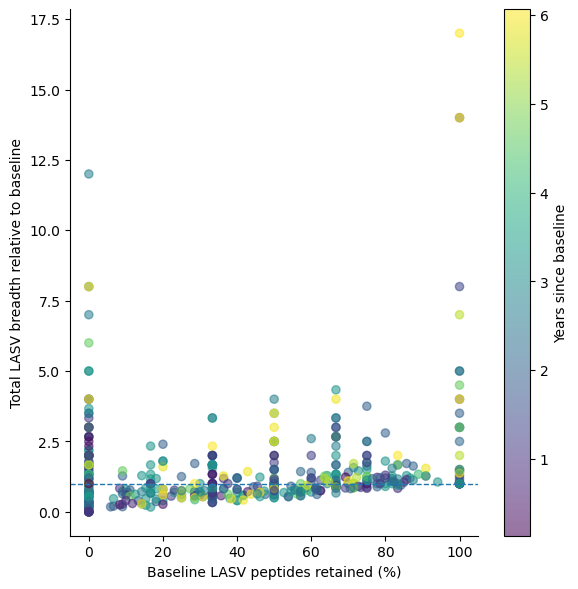

In [77]:
fig, ax = plt.subplots(figsize=(6, 6))

follow = b[b["years_since_baseline"] > 0].copy()

sc = ax.scatter(
    follow["pct_retained"],
    follow["breadth_ratio"],
    c=follow["years_since_baseline"],
    alpha=0.55,
    s=35
)

ax.axhline(1, linestyle="--", linewidth=1)

ax.set_xlabel("Baseline LASV peptides retained (%)")
ax.set_ylabel("Total LASV breadth relative to baseline")

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Years since baseline")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### drill down on one protein

In [78]:
long_lasv_hits_np = long_lasv_hits.loc[long_lasv_hits['protein_std'] == 'nucleoprotein']
trk_np = trk[trk['protein_std'] == 'nucleoprotein']

In [79]:
n_base_np = trk_np.groupby('participant_id')['peptide'].nunique().rename('n_baseline')

In [80]:
b['pct_retained']

0      100.000000
1      100.000000
2      100.000000
3        0.000000
4      100.000000
          ...    
703     37.500000
704    100.000000
705      0.000000
706    100.000000
707     78.571429
Name: pct_retained, Length: 708, dtype: float64

In [81]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

trk_np     = trk[trk['protein_std'] == 'nucleoprotein']
n_base_np  = trk_np.groupby('participant_id')['peptide'].nunique().rename('n_baseline')

# --- 1. breadth: retained / total / gained ---
retained = (trk_np.groupby(['participant_id', 'days_since_baseline'])['reactive']
                  .sum().reset_index(name='n_retained'))

total = (long_lasv_hits_np.groupby(['participant_id', 'days_since_baseline'])['reactive']
                          .sum().reset_index(name='n_total'))

b = (retained.merge(total, on=['participant_id', 'days_since_baseline'])
             .merge(n_base_np, on='participant_id'))
b['pct_retained'] = 100 * b['n_retained'] / b['n_baseline']
b['n_gained']     = b['n_total'] - b['n_retained']

# --- 2. magnitude ---
mag = (trk_np.groupby(['participant_id', 'days_since_baseline'])['z_score']
             .median().reset_index(name='median_z'))
b = b.merge(mag, on=['participant_id', 'days_since_baseline'])

# sanity: 100% at each participant's first timepoint
print(b.loc[b.groupby('participant_id')['days_since_baseline'].idxmin(), 'pct_retained'].describe())


count    159.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: pct_retained, dtype: float64


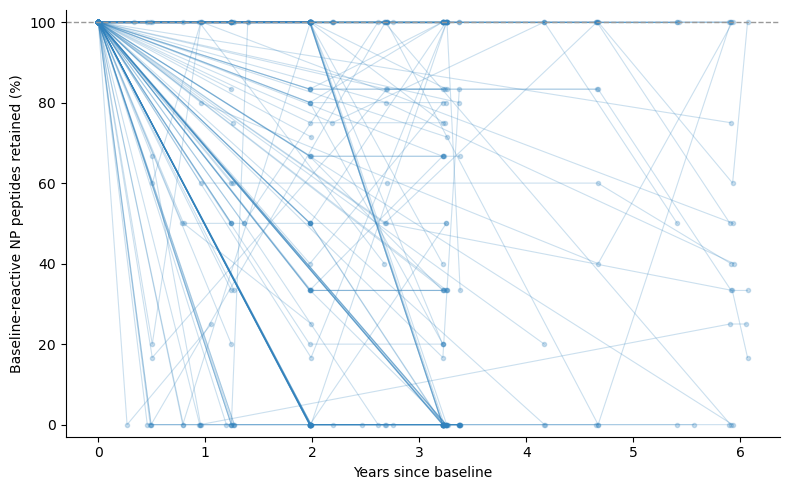

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))

for pid, g in b.sort_values('days_since_baseline').groupby('participant_id'):
    ax.plot(
        g['days_since_baseline'] / 365.25,
        g['pct_retained'],
        marker='o',
        ms=3,
        lw=0.8,
        alpha=0.25,
        color='#3182bd'
    )

ax.axhline(100, color='0.6', ls='--', lw=1)

ax.set(
    xlabel='Years since baseline',
    ylabel='Baseline-reactive NP peptides retained (%)',
    ylim=(-3, 103)
)

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#trk_np = trk.loc[trk['protein_std'] == 'nucleoprotein'].copy()

trk_np = trk

# ------------------------------------------------------------
# 1. Identify each participant's baseline visit
# ------------------------------------------------------------

baseline_day = (
    trk_np.groupby('participant_id')['days_since_baseline']
          .min()
          .rename('baseline_day')
)

trk_np = trk_np.merge(
    baseline_day,
    on='participant_id',
    how='left'
)

# ------------------------------------------------------------
# 2. Define baseline-reactive peptide repertoire
# ------------------------------------------------------------

baseline_peptides = (
    trk_np.loc[
        (trk_np['days_since_baseline'] == trk_np['baseline_day']) &
        (trk_np['reactive'] == 1),
        ['participant_id', 'peptide']
    ]
    .drop_duplicates()
)

print("Participants with >=1 baseline-reactive NP peptide:",
      baseline_peptides['participant_id'].nunique())

print("Baseline-reactive participant-peptide pairs:",
      len(baseline_peptides))

Participants with >=1 baseline-reactive NP peptide: 254
Baseline-reactive participant-peptide pairs: 1890


In [84]:
# ------------------------------------------------------------
# 3. Follow only peptides that were reactive at baseline
# ------------------------------------------------------------

long_ret = (
    trk_np.merge(
        baseline_peptides.assign(baseline_reactive=1),
        on=['participant_id', 'peptide'],
        how='inner'
    )
)

# Time relative to the participant's actual baseline
long_ret['followup_days'] = (
    long_ret['days_since_baseline'] - long_ret['baseline_day']
)

long_ret['followup_years'] = long_ret['followup_days'] / 365.25

# sanity checks
print(long_ret[['followup_days', 'followup_years']].describe())

print(
    long_ret.loc[long_ret['followup_days'] == 0, 'reactive']
            .value_counts(dropna=False)
)

       followup_days  followup_years
count    5265.000000     5265.000000
mean      629.025451        1.722178
std       632.033379        1.730413
min         0.000000        0.000000
25%         0.000000        0.000000
50%       496.000000        1.357974
75%      1175.000000        3.216975
max      2216.000000        6.067077
reactive
True    1890
Name: count, dtype: int64


In [85]:
retention = (
    long_ret
    .groupby(['participant_id', 'followup_days', 'followup_years'])
    .agg(
        n_baseline_tested=('peptide', 'nunique'),
        n_retained=('reactive', 'sum')
    )
    .reset_index()
)

retention['pct_retained'] = (
    100 *
    retention['n_retained'] /
    retention['n_baseline_tested']
)

retention.head()

,participant_id,followup_days,followup_years,n_baseline_tested,n_retained,pct_retained
0,C-110-1,0,0.000000,1,1,100.0
1,C-110-1,1187,3.249829,1,1,100.0
2,C-110-2,0,0.000000,3,3,100.0
3,C-110-2,1188,3.252567,3,0,0.0
4,C-110-3,0,0.000000,6,6,100.0


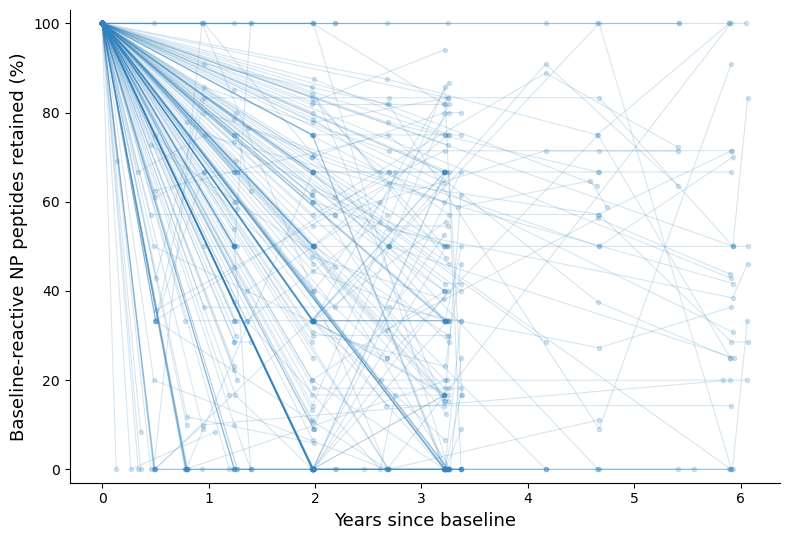

In [86]:
fig, ax = plt.subplots(figsize=(8, 5.5))

for pid, g in retention.groupby('participant_id'):

    g = g.sort_values('followup_years')

    ax.plot(
        g['followup_years'],
        g['pct_retained'],
        marker='o',
        markersize=3,
        linewidth=0.8,
        alpha=0.20,
        color='#3182bd'
    )

ax.set_xlabel('Years since baseline', fontsize=13)
ax.set_ylabel(
    'Baseline-reactive NP peptides retained (%)',
    fontsize=13
)

ax.set_ylim(-3, 103)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

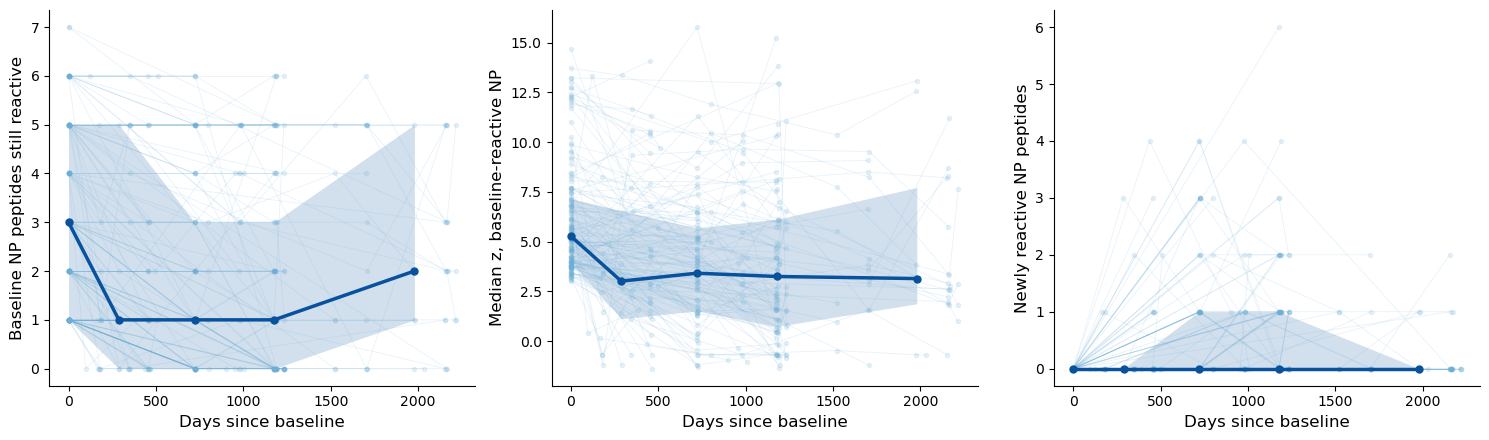

tbin
0-3m     152
6-12m     29
1-2y     101
2-4y     118
4y+       46
dtype: int64


In [87]:
import numpy as np

bins   = [0, 90, 365, 730, 1460, np.inf]
labels = ['0-3m', '6-12m', '1-2y', '2-4y', '4y+']
b['tbin'] = pd.cut(b['days_since_baseline'], bins=bins, labels=labels, right=False)
b['tmid'] = b.groupby('tbin', observed=True)['days_since_baseline'].transform('median')

panels = [('n_retained', 'Baseline NP peptides still reactive'),
          ('median_z',   'Median z, baseline-reactive NP'),
          ('n_gained',   'Newly reactive NP peptides')]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, lab) in zip(axes, panels):
    for pid, g in b.sort_values('days_since_baseline').groupby('participant_id'):
        ax.plot(g['days_since_baseline'], g[col], marker='o', ms=3,
                lw=0.6, alpha=0.15, color='#6baed6')

    agg = (b.groupby('tbin', observed=True)
             .agg(x=('tmid','first'), med=(col,'median'),
                  lo=(col, lambda s: s.quantile(.25)),
                  hi=(col, lambda s: s.quantile(.75)),
                  n=(col,'size')).dropna())
    ax.fill_between(agg['x'], agg['lo'], agg['hi'], color='#08519c', alpha=0.18, lw=0)
    ax.plot(agg['x'], agg['med'], lw=2.5, color='#08519c', marker='o', ms=5)

    ax.set_xlabel('Days since baseline', fontsize=12)
    ax.set_ylabel(lab, fontsize=12)
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print(b.groupby('tbin', observed=True).size())   # n per bin — check the tail

/tmp/ipykernel_2940698/337575727.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{l}\n(n={counts.get(l,0)})' for l in counts.index], fontsize=11)


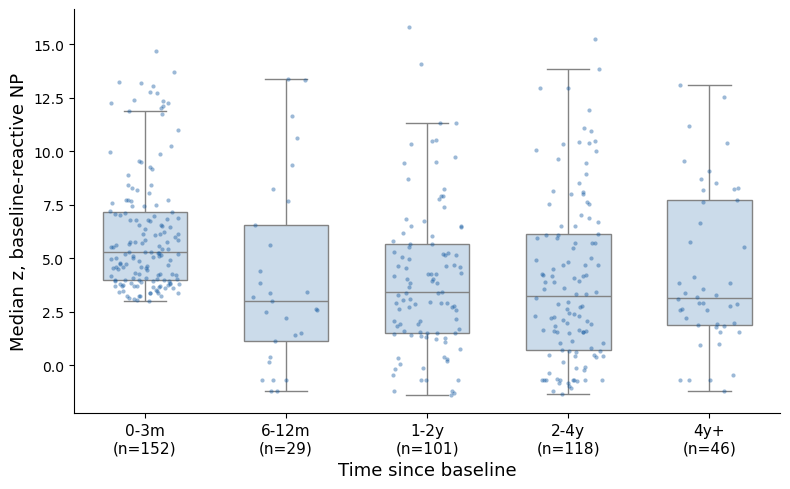

In [88]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=b, x='tbin', y='median_z', ax=ax, color='#c6dbef',
            fliersize=0, width=0.6)
sns.stripplot(data=b, x='tbin', y='median_z', ax=ax, color='#08519c',
              size=3, alpha=0.4, jitter=0.25)
ax.set_xlabel('Time since baseline', fontsize=13)
ax.set_ylabel('Median z, baseline-reactive NP', fontsize=13)
ax.spines[['top','right']].set_visible(False)

# n per bin under each box
counts = b.groupby('tbin', observed=True).size()
ax.set_xticklabels([f'{l}\n(n={counts.get(l,0)})' for l in counts.index], fontsize=11)
plt.tight_layout()

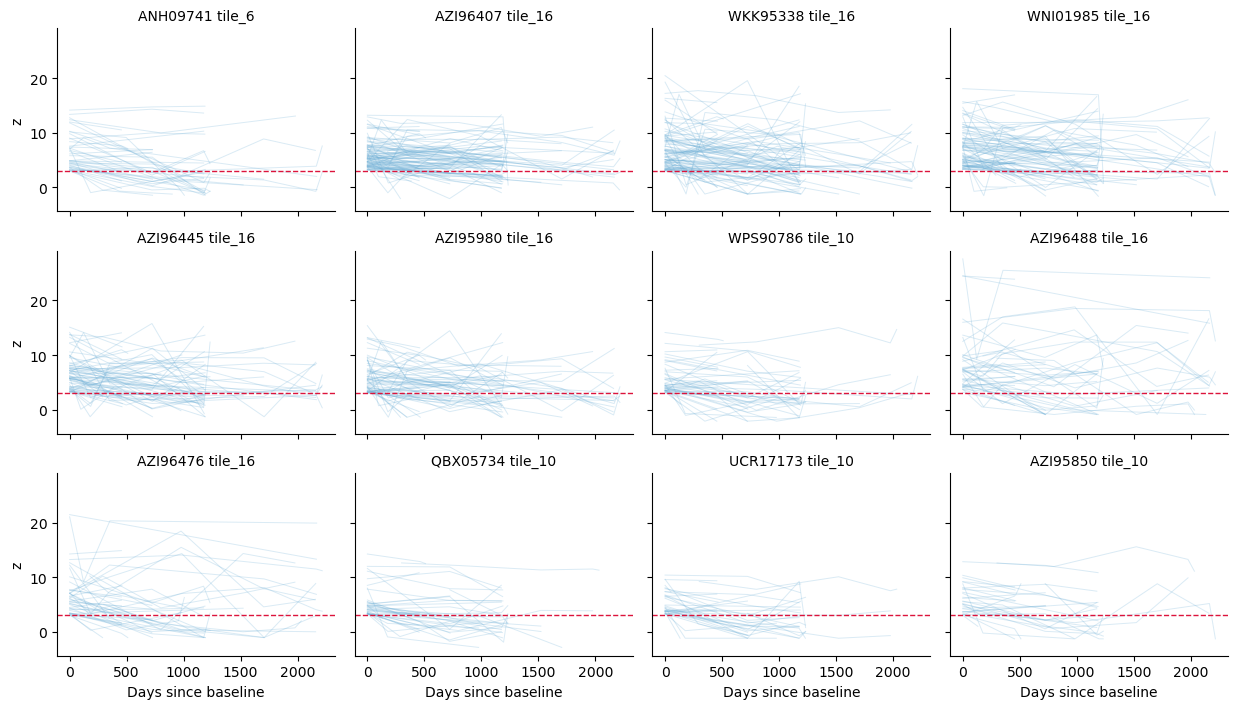

In [89]:
import seaborn as sns

def short(p):
    parts = p.split('|')
    return f"{parts[0].split('.')[0]} {parts[-1]}"   # e.g. 'ANH09741 tile_16'

trk_np = trk_np.copy()
trk_np['pep_short'] = trk_np['peptide'].map(short)

peps = trk_np['pep_short'].value_counts().head(12).index
g = sns.relplot(
    data=trk_np[trk_np.pep_short.isin(peps)],
    x='days_since_baseline', y='z_score', col='pep_short', col_wrap=4,
    kind='line', units='participant_id', estimator=None,
    color='#6baed6', alpha=0.25, lw=0.7,
    height=2.4, aspect=1.3, facet_kws={'sharey': True})
for ax in g.axes.flat:
    ax.axhline(3, ls='--', lw=1, color='crimson')
g.set_titles('{col_name}', size=10)
g.set_axis_labels('Days since baseline', 'z')
plt.tight_layout()

In [90]:
trk_np['tile'] = trk_np['peptide'].str.extract(r'tile_(\d+)$').astype(int)
trk_np['strain'] = trk_np['peptide'].str.split('|').str[0].str.split('.').str[0]

# how much redundancy is there?
print(trk_np.groupby('tile')['strain'].nunique())

collapsed = (trk_np.groupby(['participant_id','days_since_baseline','tile'])
                   .agg(z=('z','max')).reset_index())
collapsed['reactive'] = collapsed['z'] > 3

tile
1     2
3     1
4     1
6     1
7     2
9     7
10    7
11    3
12    2
13    5
16    7
17    1
20    1
21    5
32    3
34    1
39    3
40    4
41    4
42    1
43    2
49    1
56    1
58    1
69    1
73    1
82    3
83    1
85    1
90    2
95    1
Name: strain, dtype: int64


KeyError: "Column(s) ['z'] do not exist"

In [ ]:
breadth = (long_lasv_hits_np.groupby(['participant_id', 'days_since_baseline']).agg(n_reactive=('reactive', 'sum'), 
        n_peps_looked_at=('peptide', 'size')).reset_index())

breadth['pct_retained'] = 100 * breadth['n_reactive'] / breadth['n_peps_looked_at']

In [ ]:
breadth.head(30)

,participant_id,days_since_baseline,n_reactive,n_peps_looked_at,pct_retained
0,C-110-1,0,0,7,0.000000
1,C-110-1,1187,1,7,14.285714
2,C-110-2,0,2,7,28.571429
3,C-110-2,1188,1,7,14.285714
4,C-110-3,0,3,7,42.857143
5,C-110-3,1190,3,7,42.857143
6,C-110-3,1235,1,7,14.285714
7,C-111-1,0,4,7,57.142857
8,C-111-1,722,5,7,71.428571
9,C-111-1,1176,4,7,57.142857
